# 1. From raster pixels to segment objects


Compare three segmentation algorithms, turn a label image into georeferenced
polygons, attach a few measurements, and export both raster and vector results.


This notebook runs independently and creates its own small, synthetic four-band
GeoTIFF. It needs no data downloads. Use the repository checkout and install
`python -m pip install -e ".[notebooks]"` from its root, then launch `jupyter lab`.
See the [notebook setup guide](https://obia.sefa.ai/examples/) for details.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](01_segmentation.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_origin

from obia.handlers.geotif import open_geotiff
from obia.features import extract_features
from obia.segmentation import create_labels, labels_to_segments
from skimage.segmentation import mark_boundaries

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "01_segmentation"
output_dir.mkdir(parents=True, exist_ok=True)

## Make and load a tiny raster

The scene contains three invented surface types, with different values in bands
0–3 and different amounts of variation. The grid is 96 × 128 pixels at 2 m per
pixel in a projected CRS. These coordinates are only for demonstrating geospatial
operations; the scene is not an observation of a real location.

Replace this cell with `image = open_geotiff("your_image.tif")` for your own data.
The loader reads all file bands here. Its optional `bands=` argument follows
Rasterio's **one-based** file numbering; subsequent OBIA selections are zero-based.

In [2]:
rng = np.random.default_rng(42)
rows, cols = np.indices((96, 128))
reference = np.zeros(rows.shape, dtype=np.uint8)
reference[rows < 46] = 1
reference[((rows - 58) / 25) ** 2 + ((cols - 83) / 31) ** 2 < 1] = 2

# Each row contains values for bands [0, 1, 2, 3] of one surface type.
spectra = np.array([[0.48, 0.36, 0.22, 0.32],
                    [0.12, 0.38, 0.15, 0.68],
                    [0.08, 0.18, 0.30, 0.04]])
noise = np.array([0.015, 0.045, 0.006])[reference, None]
values = np.clip(spectra[reference] + rng.normal(size=(96, 128, 4)) * noise, 0, 1)
transform = from_origin(500_000, 2_200_000, 2, 2)
raster_path = output_dir / "sample.tif"
with rasterio.open(raster_path, "w", driver="GTiff", height=96, width=128,
                   count=4, dtype="float32", crs="EPSG:32604", transform=transform) as dst:
    dst.write(values.astype("float32").transpose(2, 0, 1))

image = open_geotiff(raster_path)
image.rasterio_obj.close()  # The loaded values, masks, CRS, and transform remain available.
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")

Loaded array: (96, 128, 4); CRS: EPSG:32604


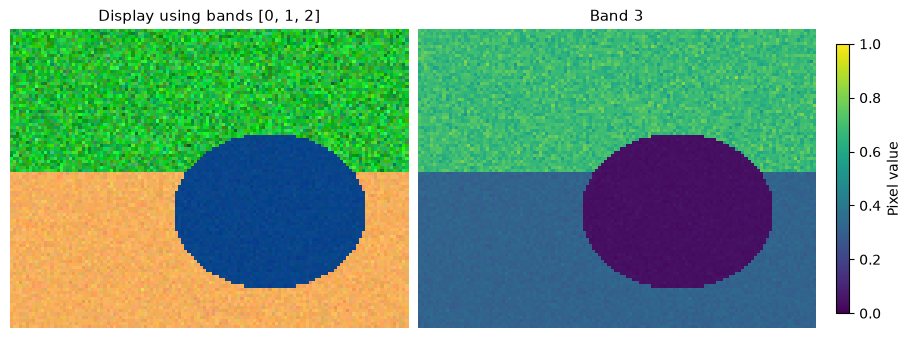

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
axes[0].imshow(image.to_image([0, 1, 2]))
axes[0].set_title("Display using bands [0, 1, 2]")
band = axes[1].imshow(image.img_data[:, :, 3], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Band 3")
fig.colorbar(band, ax=axes[1], label="Pixel value", shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

## Compare segmentation choices

SLIC controls approximate object count. Felzenszwalb groups similar neighboring
pixels, with `scale` and `min_size` influencing region size. Watershed partitions
a single-band surface into basins, here using band 3 and 100 initial markers.
Their parameters have different meanings: equal numbers do not imply equal
object sizes. Inspect the boundaries before choosing settings.

`convert2lab=False` keeps SLIC in the selected numeric band space. The four-band
input is not assumed to be an RGB image. Segmentation normalizes its inputs by
default; later feature extraction uses the original raster values.

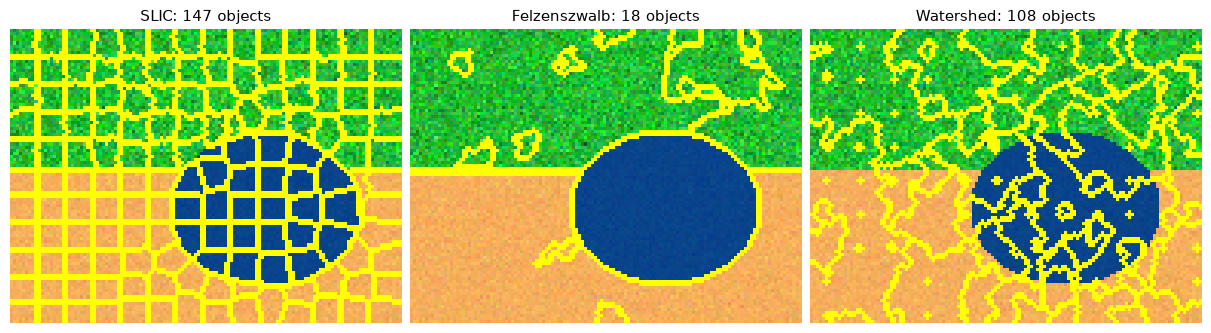

In [4]:
labels_by_method = {
    "SLIC": create_labels(
        image, segmentation_bands=[0, 1, 2, 3], method="slic",
        n_segments=160, compactness=0.2, sigma=0.6, convert2lab=False,
    ),
    "Felzenszwalb": create_labels(
        image, segmentation_bands=[0, 1, 2], method="felzenszwalb",
        scale=75, sigma=0.8, min_size=35,
    ),
    "Watershed": create_labels(
        image, segmentation_bands=[3], method="watershed", markers=100,
    ),
}

display_image = np.asarray(image.to_image([0, 1, 2]))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for ax, (name, labels) in zip(axes, labels_by_method.items()):
    ax.imshow(mark_boundaries(display_image, labels, color=(1, 1, 0), mode="inner"))
    ax.set_title(f"{name}: {np.unique(labels[labels > 0]).size} objects")
    ax.set_axis_off()
plt.show()

## Convert labels into objects

The label array stores an integer segment ID for each pixel; 0 is background.
`labels_to_segments()` turns positive IDs into polygon rows in the raster CRS.
Adding features keeps those IDs and geometries. A segment object is a row with
its geometry and measurements, not a separate kind of model input.

In [5]:
labels = labels_by_method["SLIC"]
polygons = labels_to_segments(labels, image)
objects = extract_features(
    polygons, image, bands=[0, 1, 2, 3],
    spectral=("mean", "std"), percentiles=(), shape=("area",),
)
print(f"{len(objects)} objects; shape_area is in square metres")
objects[["segment_id", "b0_mean", "b3_mean", "shape_area", "geometry"]].head()

147 objects; shape_area is in square metres


,segment_id,b0_mean,b3_mean,shape_area,geometry
0,1,0.117488,0.688527,312.0,"POLYGON ((500000 2200000, 500000 2199982, 5000..."
1,3,0.120908,0.680234,332.0,"POLYGON ((500036 2200000, 500036 2199982, 5000..."
2,10,0.118009,0.685083,324.0,"POLYGON ((500162 2200000, 500162 2199982, 5001..."
3,11,0.116489,0.672721,320.0,"POLYGON ((500180 2200000, 500180 2199982, 5001..."
4,14,0.120571,0.683411,360.0,"POLYGON ((500236 2200000, 500236 2199982, 5002..."


## Export for GIS use

The GeoPackage contains the object polygons and feature table. The GeoTIFF
contains segment IDs on the original raster grid. Neither output is a class map:
classification comes after objects have training labels.

In [6]:
objects.to_file(output_dir / "segments.gpkg", layer="objects", driver="GPKG")
with rasterio.open(output_dir / "segment_ids.tif", "w", driver="GTiff",
                   height=labels.shape[0], width=labels.shape[1], count=1,
                   dtype="int32", crs=image.crs, transform=image.transform, nodata=0) as dst:
    dst.write(labels.astype("int32"), 1)

saved_objects = gpd.read_file(output_dir / "segments.gpkg", layer="objects")
assert len(saved_objects) == len(objects)
assert saved_objects.crs == objects.crs
print(f"Saved {len(saved_objects)} objects to {output_dir / 'segments.gpkg'}")

Saved 147 objects to example_outputs/01_segmentation/segments.gpkg


Try changing SLIC's `n_segments` to 80 or 300 and rerun from the comparison cell.
How do boundaries and object areas change?

Continue with [raster object features](https://obia.sefa.ai/examples/02_raster_features/) or consult the
[segmentation guide](https://obia.sefa.ai/usage/segmentation/) for seeded and contour methods.